# Sammanfattning/Slutsats-Vad säljer vi?

Electronics är den ledande produktkategprin med cirka 39% av den totala omsättningen och cirka 23% av sålda enheter. Kategorin har även högst genomsnittlig intäkt per såld enhet, cirka 778 kr. 

Clothing har högre försäljningsvolym än Sports, men Sports genererar både högre total omsättning och högre genomsnittlig intäkt per såld enhet. 

Resultatet visar att både försäljningsvolym och genomsnittlig intäkt per enhet är viktiga för att förstå vilka kategorier som bidrar mest till omsättningen.

Rekommendation: 

Sports och Electronics är intressanta kategorier att prioritera inför kommande satsningar. Men för att avgöra lönsamma satsningar behöver vi även vet kostnader och vinstmarginaler. Innan man gör några stora satsninsgar på produktkategorierna Toys och Beaty, kan det vara värt att göra en fördjupad lönsamhetsanalys. Den bör omfatta både direkta kostnader och resursåtgång, exempelvis lagerhållning och arbetskraft. Utifrån resultaten kan vi bedöma om det är mer fördelaktigt att satsa på ökad försäljning eller överväga att avveckla någon av kategorierna.



## 1. Import och inläsning av data

Vi använder biblioteket `pandas` för att läsa in och analysera försäljningsdata. Därefter granskar vi de första raderna för att få en överblick över datasetets struktur.



In [2]:
import pandas as pd

In [3]:
df=pd.read_csv("../data/ecommerce_sales.csv")
df.head()

,order_id,date,city,category,price,units,revenue
0,100000,2024-04-19,Stockholm,Sports,530.95,4,2123.80
1,100001,2024-05-06,Malmö,Sports,653.28,3,1959.84
2,100002,2024-03-07,Uppsala,Clothing,177.98,4,711.92
3,100003,2024-04-08,Göteborg,Home,348.57,3,1045.71
4,100004,2024-01-18,Uppsala,Electronics,777.07,3,2331.21


## 2. Intäkter per produktkategori

Vi undersöker vilka produktkategorier som finns i datasetet och beräknar den totala intäkten för varje kategori.

Genom att gruppera försäljningen efter kategori och summera intäkterna kan vi identifiera vilka kategorier som bidrar mest till den totala omsättningen.

In [16]:
df["category"].unique()

<StringArray>
['Sports', 'Clothing', 'Home', 'Electronics', 'Toys', 'Beauty']
Length: 6, dtype: str

In [31]:
#Intäkter per kategori samt andel intäkter per kategori.
intakter_per_kategori=df.groupby("category")["revenue"].sum().sort_values(ascending=False)
print(intakter_per_kategori.round(0))
total_intakt=df["revenue"].sum()
andel_intakter_per_kategori=(intakter_per_kategori/total_intakt)*100
print(andel_intakter_per_kategori.round(0))

category
Electronics    1364228.0
Sports          734653.0
Clothing        586745.0
Home            511071.0
Beauty          163054.0
Toys            143016.0
Name: revenue, dtype: float64
category
Electronics    39.0
Sports         21.0
Clothing       17.0
Home           15.0
Beauty          5.0
Toys            4.0
Name: revenue, dtype: float64


In [32]:
#Antal sålda per kategori samt andel sålda per kategori.
antal_salda_per_kategori=df.groupby("category")["units"].sum().sort_values(ascending=False)
print(antal_salda_per_kategori)
totalt_antal_salda=df["units"].sum()
andel_salda_per_kategori=(antal_salda_per_kategori/totalt_antal_salda)*100
print(andel_salda_per_kategori.round(0))

category
Electronics    1753
Clothing       1655
Sports         1401
Home           1278
Toys            717
Beauty          659
Name: units, dtype: int64
category
Electronics    23.0
Clothing       22.0
Sports         19.0
Home           17.0
Toys           10.0
Beauty          9.0
Name: units, dtype: float64


## 3. Genomsnittlig intäkt per såld enhet
Vi undersöker vilken produktkategori som genererar högst genomsnittlig intäkt per såld enhet. Detta gör vi genom att dividera den totala intäkten för varje kategori med antalet sålda enheter inom samma kategori.

In [30]:
#Medelintäkt per såld enhet.
medel_intakt_per_enhet=intakter_per_kategori/antal_salda_per_kategori
medel_intakt_per_enhet=medel_intakt_per_enhet.sort_values(ascending=False).round(0)
print(medel_intakt_per_enhet)

category
Electronics    778.0
Sports         524.0
Home           400.0
Clothing       355.0
Beauty         247.0
Toys           199.0
dtype: float64


## 4. Visualisering av försäljningen
För att tydliggöra försäljningsresultaten visualiseras den totala intäkten och antalet sålda enheter per produktkategori i två stapeldiagram.

Diagrammen gör det möjligt att jämföra kategoriernas omsättning och försäljningsvolym.

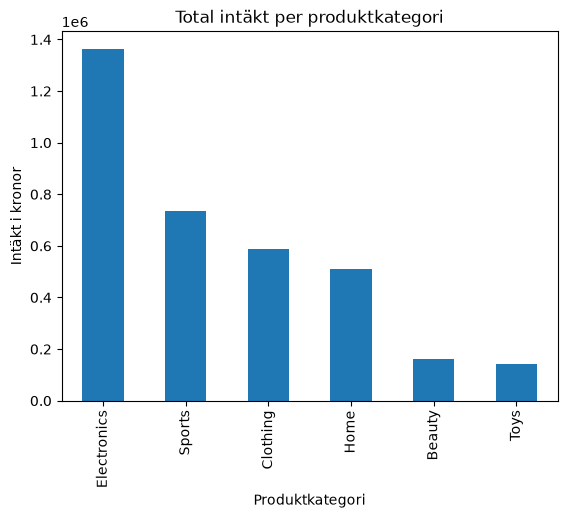

In [33]:
import matplotlib.pyplot as plt
intakter_per_kategori.plot(kind="bar")
plt.title("Total intäkt per produktkategori")
plt.xlabel("Produktkategori")
plt.ylabel("Intäkt i kronor")
plt.show()

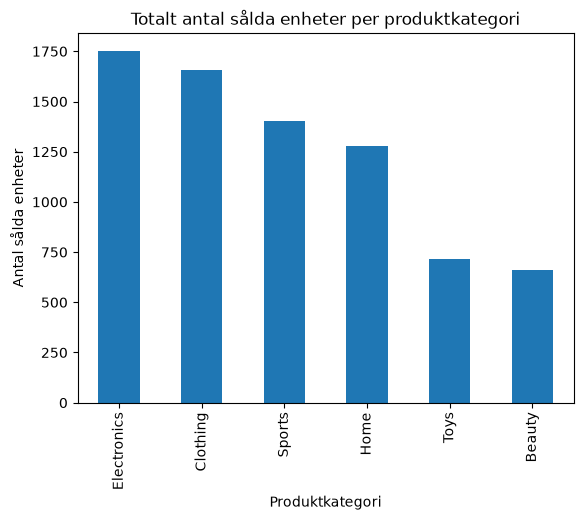

In [34]:
antal_salda_per_kategori.plot(kind="bar")
plt.title("Totalt antal sålda enheter per produktkategori")
plt.xlabel("Produktkategori")
plt.ylabel("Antal sålda enheter")
plt.show()